# 07 — Model Evaluation (Week 8)
**Goal:** judge the models with more than R², find where the best model is strong and weak, and save `metrics_summary.csv`.

Same data, features (Week 6 set D) and split (train May 2025 – Apr 2026, test May 2026) as Weeks 6–7.

| Section | Question it answers |
|---|---|
| 1. Metrics beyond R² | How far off is a typical prediction, in dollars and in %? |
| 2. Error breakdown | Which price ranges and counties does the model handle best and worst? Does it lean high or low? |
| 3. Price ranges (conformal prediction) | Can the model give a range like "$780K–$910K" that really contains the price 90% of the time? |
| 4. Walk-forward backtest | Does the accuracy hold up month after month, or was May 2026 lucky? |

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

pd.set_option("display.float_format", "{:,.3f}".format)

TARGET = "ClosePrice"
BASE_NUMERIC = ["LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
                "YearBuilt", "GarageSpaces", "Stories", "Latitude", "Longitude"]
BINARY = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]
ENGINEERED = ["Age", "BedBathRatio", "SqftPerBedroom"]
FEATURE_SET_D = dict(numeric=BASE_NUMERIC + ENGINEERED, encode_cols=["PostalCode", "SchoolDistrict"], comps=True)

# settings chosen on April 2026 in 06_advanced_models.ipynb (shown there rounded to 3 decimals)
LGB_PARAMS = dict(learning_rate=0.05, num_leaves=134, min_child_samples=25, subsample=0.784, subsample_freq=1,
                  colsample_bytree=0.313, reg_lambda=0.295, n_estimators=1054)
XGB_PARAMS = dict(max_depth=6, learning_rate=0.1, n_estimators=1288, subsample=0.8, colsample_bytree=0.8)

`smoothed_price()`, `comps_price()` and `prepare()` are copied unchanged from `05_feature_engineering.ipynb`.

In [2]:
SMOOTHING = 20     # sales a group needs before its own average outweighs the statewide one
K_COMPS = 10


def smoothed_price(train, test, col):
    """Each group's average log price, pulled toward the overall average when the group is small. Training rows only."""
    log_price = np.log(train[TARGET])
    overall = log_price.mean()
    stats = log_price.groupby(train[col]).agg(["mean", "count"])
    value = (stats["count"] * stats["mean"] + SMOOTHING * overall) / (stats["count"] + SMOOTHING)
    return train[col].map(value), test[col].map(value).fillna(overall)


def comps_price(train, test, k=K_COMPS):
    """Median log price-per-sq-ft of the k nearest TRAINING sales. A training home never counts itself."""
    to_radians = lambda d: np.radians(d[["Latitude", "Longitude"]].to_numpy())
    tree = BallTree(to_radians(train), metric="haversine")
    ppsf = np.log(train[TARGET] / train["LivingArea"]).to_numpy()

    _, idx_train = tree.query(to_radians(train), k=k + 1)
    own = idx_train == np.arange(len(train))[:, None]
    own[~own.any(axis=1), -1] = True           # self not returned (tied with an identical location): drop the farthest
    idx_train = idx_train[~own].reshape(len(train), k)

    _, idx_test = tree.query(to_radians(test), k=k)
    return np.median(ppsf[idx_train], axis=1), np.median(ppsf[idx_test], axis=1)

In [3]:
def prepare(train, test, numeric, encode_cols, comps=False):
    X_tr, X_te = pd.DataFrame(index=train.index), pd.DataFrame(index=test.index)

    # median fill + "was missing" flags
    medians = train[numeric].median()
    for col in numeric:
        if train[col].isna().any():
            X_tr[f"{col}_missing"] = train[col].isna().astype(int)
            X_te[f"{col}_missing"] = test[col].isna().astype(int)
        X_tr[col], X_te[col] = train[col].fillna(medians[col]), test[col].fillna(medians[col])
    for col in ["LivingArea", "LotSizeSquareFeet"]:
        X_tr[col], X_te[col] = np.log1p(X_tr[col]), np.log1p(X_te[col])
    for col in BINARY:
        X_tr[col], X_te[col] = train[col], test[col]

    # location-price features, learned from training sales only
    scale_cols = list(numeric)
    for col in encode_cols:
        X_tr[f"{col}Price"], X_te[f"{col}Price"] = smoothed_price(train, test, col)
        scale_cols.append(f"{col}Price")
    if comps:
        X_tr["CompsPricePerSqft"], X_te["CompsPricePerSqft"] = comps_price(train, test)
        scale_cols.append("CompsPricePerSqft")

    # county one-hot: test gets exactly the training columns
    county_tr = pd.get_dummies(train["CountyOrParish"], prefix="CountyOrParish", dtype=int)
    county_te = pd.get_dummies(test["CountyOrParish"], prefix="CountyOrParish", dtype=int).reindex(
        columns=county_tr.columns, fill_value=0)
    X_tr, X_te = X_tr.join(county_tr), X_te.join(county_te)

    scaler = StandardScaler().fit(X_tr[scale_cols])
    X_tr[scale_cols], X_te[scale_cols] = scaler.transform(X_tr[scale_cols]), scaler.transform(X_te[scale_cols])
    return X_tr, X_te, np.log(train[TARGET]), test[TARGET]

In [4]:
df = pd.read_csv("features_sfr.csv", parse_dates=["CloseDate"], dtype={"PostalCode": str})
month = df["CloseDate"].dt.to_period("M")
train, test = df[df["Split"] == "train"], df[df["Split"] == "test"]
X_train, X_test, y_train, y_test = prepare(train, test, **FEATURE_SET_D)
print(f"Train {len(X_train):,} sales (May 2025 – Apr 2026), test {len(X_test):,} sales (May 2026)")

Train 106,696 sales (May 2025 – Apr 2026), test 11,991 sales (May 2026)


## 1. Metrics beyond R²
| Metric | Plain meaning | Why it matters |
|---|---|---|
| **MAE** | Average miss, in dollars | Easy to explain to anyone |
| **RMSE** | Like MAE, but big misses count extra | Punishes the rare $1M miss |
| **MAPE** | Average miss, as % of the price | A $50K miss is huge on a $300K home, small on a $3M one |
| **MdAPE** | *Median* miss as % of the price: half the homes are closer than this | The "typical home" number; not dragged around by a few wild misses |
| **Within 10% / 20%** | Share of homes priced within 10% (20%) of the sale price | How online home-value estimators usually report accuracy |
| **R²** | Share of price variation explained | What we've used so far; dominated by expensive homes, since it's in dollars |

In [5]:
def metrics(actual, pred):
    pct = np.abs(pred - actual) / actual
    return {"MAE": np.mean(np.abs(pred - actual)), "RMSE": np.sqrt(np.mean((pred - actual) ** 2)),
            "MAPE": pct.mean(), "MdAPE": np.median(pct),
            "within_10pct": (pct <= 0.10).mean(), "within_20pct": (pct <= 0.20).mean(),
            "R2": r2_score(actual, pred)}


models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, max_features=0.33,
                                           n_jobs=-1, random_state=0),
    "XGBoost (grid-tuned)": xgb.XGBRegressor(tree_method="hist", n_jobs=-1, random_state=0, **XGB_PARAMS),
    "LightGBM (Optuna-tuned)": lgb.LGBMRegressor(verbose=-1, n_jobs=-1, random_state=0, **LGB_PARAMS),
}
predictions, rows = {}, []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = np.exp(model.predict(X_test))
    rows.append({"model": name, **metrics(y_test, predictions[name])})

summary = pd.DataFrame(rows).set_index("model")
summary.to_csv("metrics_summary.csv")

show = summary.copy()
show[["MAE", "RMSE"]] = show[["MAE", "RMSE"]].map(lambda v: f"${v:,.0f}")
for col in ["MAPE", "MdAPE", "within_10pct", "within_20pct"]:
    show[col] = show[col].map(lambda v: f"{v:.1%}")
show["R2"] = show["R2"].map(lambda v: f"{v:.3f}")
show

,MAE,RMSE,MAPE,MdAPE,within_10pct,within_20pct,R2
model,,,,,,,
Linear Regression,"$192,760","$467,164",13.8%,9.8%,50.5%,79.6%,0.866
Random Forest,"$173,109","$436,521",12.0%,8.0%,59.1%,83.6%,0.883
XGBoost (grid-tuned),"$168,525","$429,594",11.6%,7.9%,59.4%,84.8%,0.886
LightGBM (Optuna-tuned),"$167,206","$432,568",11.5%,7.8%,59.7%,85.2%,0.885


**Reading the table**
* **LightGBM is best or tied on almost every metric:** typical (median) error **7.8%**, average error 11.5%, **60% of homes priced within 10%** and **85% within 20%**. XGBoost is essentially tied; Linear Regression trails clearly (only half within 10%).
* **MAPE (11.5%) is well above MdAPE (7.8%).** Most homes are priced closely, but a minority of big misses pulls the average up. That's why we report the median as the "typical home" number.
* **The dollar metrics look large ($167K MAE, $433K RMSE)** because a few multi-million-dollar homes dominate them. RMSE being 2.6× MAE says the same thing: a small number of very large misses. In % terms the picture is much better.
* All metrics are saved to `metrics_summary.csv`.

## 2. Where the best model is strong and weak
From here on: **LightGBM (Optuna-tuned)**, Week 7's pick.

Besides the size of each miss (MdAPE), we look at its **direction**: the median *signed* error. Negative means the model tends to **under-price** that group, positive means **over-price**.

In [6]:
best = "LightGBM (Optuna-tuned)"
pred = predictions[best]
ev = test[["CountyOrParish", TARGET]].assign(pred=pred,
                                              pct_err=np.abs(pred - y_test) / y_test,
                                              signed_err=(pred - y_test) / y_test)


def breakdown(group):
    return ev.groupby(group, observed=True).agg(
        sales=(TARGET, "size"), median_price=(TARGET, "median"),
        MdAPE=("pct_err", "median"), within_10pct=("pct_err", lambda s: (s <= 0.10).mean()),
        median_signed_err=("signed_err", "median"))


ev["price_band"] = pd.qcut(ev[TARGET], 5, labels=["cheapest 20%", "20–40%", "40–60%", "60–80%", "priciest 20%"])
breakdown("price_band")

,sales,median_price,MdAPE,within_10pct,median_signed_err
price_band,,,,,
cheapest 20%,2411,"449,990.000",0.073,0.622,0.009
20–40%,2387,"699,000.000",0.058,0.710,-0.008
40–60%,2432,"930,000.000",0.069,0.659,-0.014
60–80%,2366,"1,355,000.000",0.089,0.551,-0.034
priciest 20%,2395,"2,400,000.000",0.115,0.443,-0.065


In [7]:
counties = breakdown("CountyOrParish").query("sales >= 200").sort_values("MdAPE")
counties

,sales,median_price,MdAPE,within_10pct,median_signed_err
CountyOrParish,,,,,
Riverside,1792,"635,312.000",0.059,0.684,-0.010
San Bernardino,1179,"550,000.000",0.065,0.680,-0.020
Ventura,412,"1,025,000.000",0.076,0.612,-0.025
Orange,1168,"1,477,500.000",0.076,0.610,-0.029
Contra Costa,598,"962,500.000",0.076,0.609,-0.022
San Diego,1310,"1,086,500.000",0.082,0.581,-0.022
Los Angeles,2920,"1,054,502.500",0.087,0.555,-0.017
San Luis Obispo,203,"995,000.000",0.093,0.532,-0.015
Santa Clara,410,"1,964,000.000",0.093,0.529,-0.011


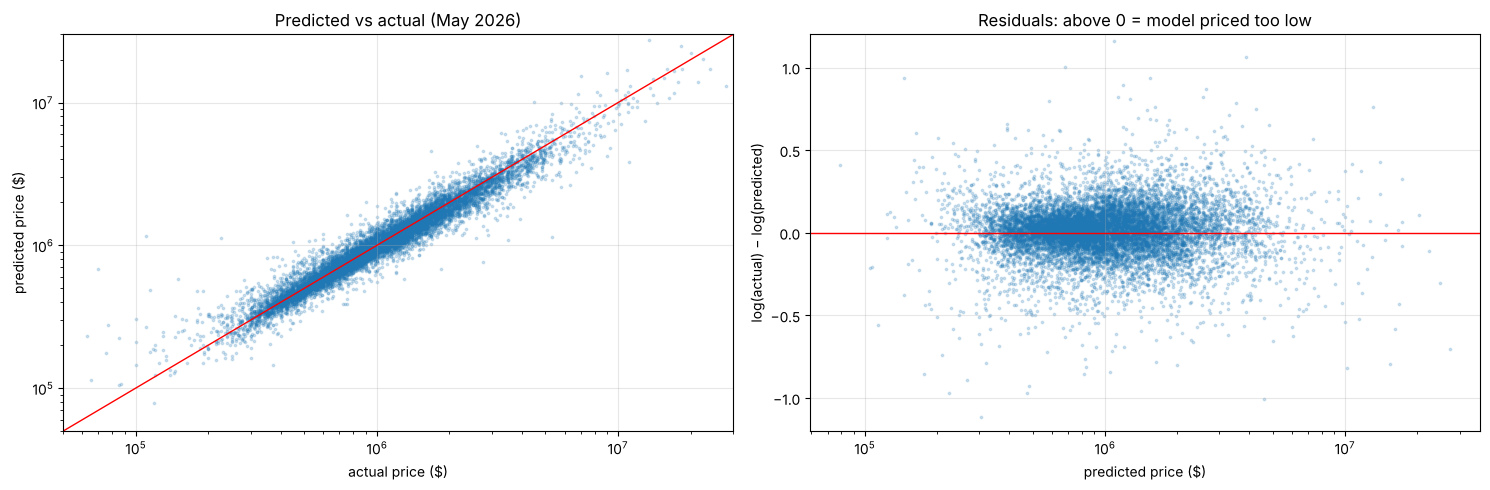

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
lims = [5e4, 3e7]
axes[0].scatter(y_test, pred, s=3, alpha=0.2)
axes[0].plot(lims, lims, color="red", lw=1)
axes[0].set(xscale="log", yscale="log", xlim=lims, ylim=lims, xlabel="actual price ($)",
            ylabel="predicted price ($)", title="Predicted vs actual (May 2026)")

log_resid = np.log(y_test) - np.log(pred)
axes[1].scatter(pred, log_resid, s=3, alpha=0.2)
axes[1].axhline(0, color="red", lw=1)
axes[1].set(xscale="log", ylim=(-1.2, 1.2), xlabel="predicted price ($)",
            ylabel="log(actual) − log(predicted)", title="Residuals: above 0 = model priced too low")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**What the breakdown shows**
* **Error grows with price:** about 6% typical error for $600K–$800K homes, **11.5% for the priciest 20%** (median $2.4M). Only 44% of luxury homes are priced within 10%, vs 71% in the 20–40% band.
* **The model under-prices expensive homes:** a median signed error of **−6.5%** for the top band, while cheap homes are about right (+0.9%). This is *regression toward the mean*: when the features can't explain why a home is exceptional (views, finishes, lot quality), the model pulls its guess toward ordinary prices.
* **Inland counties are easiest, the Bay Area and Central Coast hardest:** Riverside and San Bernardino ≈ 6% typical error; Santa Clara, Alameda and San Luis Obispo ≈ 9%. Pricier, more varied markets are harder.
* **Every county leans slightly low** (−1% to −3%). The model learns from the past 12 months, and May is spring selling season, when prices tend to run above the yearly average. A time-trend or month feature is a natural next fix.

## 3. Price ranges with conformal prediction
A single number ("$845K") hides how sure the model is. A range ("$780K–$910K, 90% confidence") is more useful, **if the 90% is real**. **Split conformal prediction** makes it real with three steps:

1. **Train** the model on 11 months (May 2025 – Mar 2026).
2. **Calibrate** on the next month (April 2026), which the model hasn't seen: measure how far off each prediction is. Take the 90th percentile of those misses, call it *q*.
3. **Predict** May 2026 as *prediction ± q*. On the log scale, ± q becomes ×/÷ e^q, so the range scales with the price.

If the next month's errors behave like April's, about 90% of May's ranges will contain the true price. That's the only assumption, which is why we **check** it instead of trusting it.

In [9]:
available = sorted(month.unique())
COVERAGE = 0.90


def conformal_month(test_month, train_months=11):
    """Train on `train_months` months, calibrate on the latest available month before `test_month`, test on it."""
    test_month = pd.Period(test_month, "M")
    calib_month = max(m for m in available if m < test_month)
    tr = df[(month >= calib_month - train_months) & (month < calib_month)]
    cal_test = df[(month == calib_month) | (month == test_month)]
    X_tr, X_ct, y_tr, price_ct = prepare(tr, cal_test, **FEATURE_SET_D)

    model = lgb.LGBMRegressor(verbose=-1, n_jobs=-1, random_state=0, **LGB_PARAMS).fit(X_tr, y_tr)
    log_pred = pd.Series(model.predict(X_ct), index=X_ct.index)
    is_cal = month[X_ct.index] == calib_month

    misses = np.abs(np.log(price_ct[is_cal]) - log_pred[is_cal]).sort_values().to_numpy()
    n = len(misses)
    q = misses[int(np.ceil((n + 1) * COVERAGE)) - 1]    # conformal quantile: a hair above the plain 90th percentile

    out = pd.DataFrame({"actual": price_ct[~is_cal], "pred": np.exp(log_pred[~is_cal])})
    out["low"], out["high"] = out["pred"] * np.exp(-q), out["pred"] * np.exp(q)
    out["covered"] = out["actual"].between(out["low"], out["high"])
    return out, q, calib_month


intervals, q, calib = conformal_month("2026-05")
print(f"Calibrated on {calib}: q = {q:.3f}, so each range is the prediction ×/÷ {np.exp(q):.2f} "
      f"(−{1 - np.exp(-q):.0%} to +{np.exp(q) - 1:.0%})")
print(f"Coverage on May 2026: {intervals['covered'].mean():.1%} of ranges contain the sale price (target 90%)")

Calibrated on 2026-04: q = 0.254, so each range is the prediction ×/÷ 1.29 (−22% to +29%)
Coverage on May 2026: 90.1% of ranges contain the sale price (target 90%)


In [10]:
examples = intervals.sample(6, random_state=1).sort_values("actual")
examples[["actual", "pred", "low", "high"]].map(lambda v: f"${v:,.0f}").assign(covered=examples["covered"])

,actual,pred,low,high,covered
292059,"$515,000","$511,072","$396,437","$658,857",True
291680,"$565,000","$539,071","$418,155","$694,952",True
289375,"$700,000","$614,287","$476,500","$791,917",True
288200,"$740,000","$661,502","$513,124","$852,785",True
293340,"$1,400,000","$1,374,607","$1,066,277","$1,772,096",True
291553,"$3,220,000","$2,830,954","$2,195,959","$3,649,568",True


### Is the coverage fair across price ranges?

In [11]:
bands = pd.qcut(intervals["actual"], 5, labels=["cheapest 20%", "20–40%", "40–60%", "60–80%", "priciest 20%"])
intervals.groupby(bands, observed=True)["covered"].mean().to_frame("coverage").T

actual,cheapest 20%,20–40%,40–60%,60–80%,priciest 20%
coverage,0.876,0.953,0.945,0.913,0.819


**What the ranges show**
* **Overall coverage is right on target: 90.1%** of May's ranges contain the sale price. The range is the prediction −22% / +29%.
* **But coverage is uneven across prices:** about 95% in the middle bands (the range is wider than it needs to be there) and only **82% for the priciest 20%** (too narrow). That's the cost of giving every home the same %-width range while the model is less certain about luxury homes.
* **Fix for later:** calibrate separately by price range ("Mondrian" conformal) or use quantile regression to predict a home-specific width. Both keep the 90% guarantee *within each band*.

## 4. Walk-forward backtest
One test month can be lucky. A **walk-forward backtest** repeats the whole process for each of the last 12 months with data, always training only on the past: train on 11 months, calibrate on the next, test on the month after. It's the closest thing to running the model live for a year.

In [12]:
test_months = available[-12:]
start, rows = time.time(), []
for m in test_months:
    out, q_m, cal_m = conformal_month(m)
    rows.append({"test_month": str(m), "calibrated_on": str(cal_m), "sales": len(out),
                 **{k: v for k, v in metrics(out["actual"], out["pred"]).items() if k in ("R2", "MdAPE", "within_10pct")},
                 "range_coverage": out["covered"].mean(), "range_half_width": np.exp(q_m) - 1})
backtest = pd.DataFrame(rows).set_index("test_month")
print(f"12 months in {time.time() - start:.0f} s")
backtest

12 months in 335 s


,calibrated_on,sales,MdAPE,within_10pct,R2,range_coverage,range_half_width
test_month,,,,,,,
2025-04,2025-03,11833,0.077,0.605,0.855,0.896,0.269
2025-05,2025-04,11720,0.075,0.614,0.875,0.899,0.272
2025-06,2025-05,11656,0.074,0.620,0.863,0.903,0.273
2025-07,2025-06,12083,0.074,0.615,0.881,0.897,0.266
2025-10,2025-07,11987,0.077,0.603,0.883,0.894,0.267
2025-11,2025-10,9704,0.079,0.600,0.885,0.897,0.278
2025-12,2025-11,10424,0.077,0.596,0.899,0.895,0.282
2026-01,2025-12,7458,0.079,0.593,0.888,0.893,0.287
2026-02,2026-01,8520,0.078,0.595,0.870,0.906,0.300


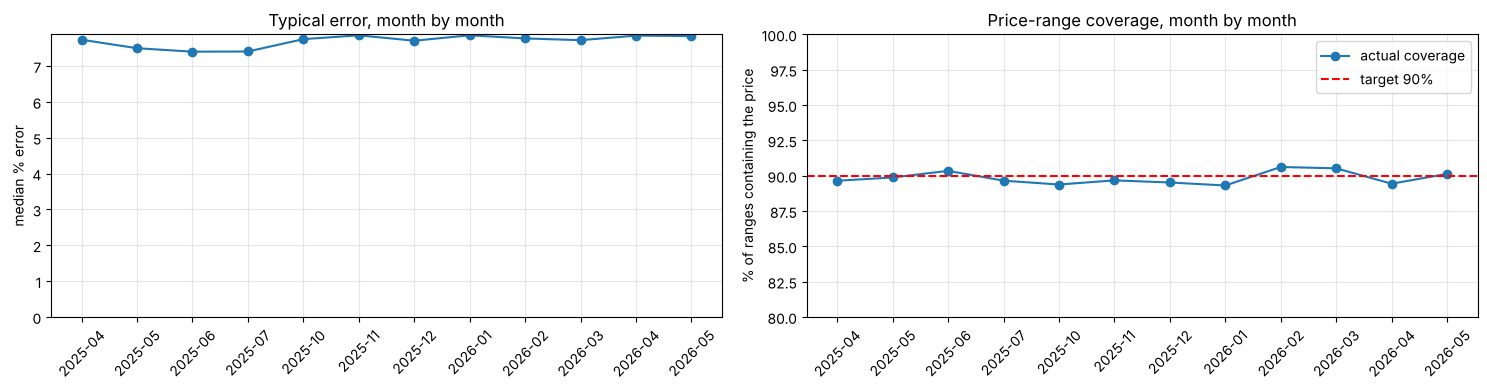

        R2  MdAPE  within_10pct  range_coverage
mean 0.879  0.077         0.602           0.898
min  0.855  0.074         0.591           0.893
max  0.899  0.079         0.620           0.906


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(backtest.index, backtest["MdAPE"] * 100, marker="o")
axes[0].set(ylabel="median % error", title="Typical error, month by month", ylim=(0, None))
axes[1].plot(backtest.index, backtest["range_coverage"] * 100, marker="o", label="actual coverage")
axes[1].axhline(90, color="red", ls="--", label="target 90%")
axes[1].set(ylabel="% of ranges containing the price", title="Price-range coverage, month by month", ylim=(80, 100))
axes[1].legend()
for ax in axes:
    ax.tick_params(axis="x", rotation=45); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(backtest[["R2", "MdAPE", "within_10pct", "range_coverage"]].agg(["mean", "min", "max"]))

**What the backtest shows**
* **Accuracy is stable, not a lucky month:** over 12 months, typical error stays between **7.4% and 7.9%**, R² between 0.855 and 0.899, and about 60% of homes are within 10% every month.
* **The 90% ranges held up every month: coverage 89.3%–90.6%**, average 89.8%. Conformal prediction's promise worked in practice on new months, not just on one test.
* **Slight drift to watch:** typical error crept from 7.4% to 7.8% and the ranges widened from about ±27% to ±29% over the year. Either the market got a little harder to predict or the features are aging. In production you'd monitor this and retrain monthly.
* The backtest trains on 11 months (one month is held back for calibration), so its May 2026 row differs slightly from section 1's 12-month model.

## Summary
* **Best model: LightGBM (Optuna-tuned).** On May 2026: typical error **7.8%**, average 11.5%, **60% of homes within 10%**, 85% within 20%, R² 0.885. Saved to `metrics_summary.csv` with the other three models.
* **Weak spots:** luxury homes (11.5% typical error, under-priced by about 6.5%) and expensive, varied markets (Bay Area, San Luis Obispo). All counties lean slightly low in May, likely spring prices running above the 12-month average.
* **Price ranges:** split conformal prediction gives every home a 90% range (−22% / +29%). It hit **90.1% coverage on May** and **89.3–90.6% in every one of 12 walk-forward months**, though coverage is lower for luxury homes (82%).
* **Next steps:** price-range-specific calibration for fairer ranges, and a time-trend feature to fix the seasonal under-pricing.